# 09 · FHN square lattice: four nearest neighbors
## Goal
Advance from the verified pair to a homogeneous 6×6 square lattice. Compare open and periodic boundaries, fixed per-edge weights and row-normalized input, and two reproducible initial-phase realizations. Keep topology, interaction and observation definitions separate.

All variables and time are dimensionless. This is a finite deterministic experiment, not a complete phase diagram, statistical ensemble estimate or biological tissue model. Figures, event times, initial conditions and results are saved in `results/fhn_lattice/`. Requires NumPy, SciPy, pandas, Matplotlib and Jupyter; no downloads or external data.

## Observed results
All **24 lattice experiments** executed and **24 structural/numerical checks** passed. The open graph has 60 undirected edges and spectral gap 0.2679491924; the periodic graph has 72 edges and gap 1. The periodic per-edge g=0.1 and normalized g=0.4 trajectories agree exactly in this implementation.

At seed 11, open per-edge g=0.1 gives RMS state spread 0.00152681 in time 600–1200, falling to 5.19155×10⁻⁷ in time 1800–2400. This is evidence of a continuing transient, not a settled nonuniform state. Periodic per-edge g=0.1 has RMS spread 1.7037e-07 in the first window. Boundaries alter both edges and the Laplacian spectrum; this small experiment does not isolate a universal boundary effect.

Open normalized g=0.1 remains strongly sensitive to the initial realization within the first window: mean phase order is 0.355532 for seed 11 versus 0.984736 for seed 29. Longer-window validation above applies only to the selected **per-edge** case; distinct attractors are not established for these normalized runs. Low global order alone does not classify a wave or disorder.

For the selected tighter-tolerance comparison, maximum state discrepancy is 4.534×10⁻⁷ and maximum event-time discrepancy is 3.156×10⁻⁷. Both use DOP853 at different tolerances; this is not an independent-solver comparison. Phase-order averages exclude unsupported endpoint times; valid-time fractions are saved with every run.


## Setup and experiment design
Keep $a=0.7,b=0.8,\epsilon=0.08,I_i=0.5$ from notebooks 04/08:
$$\dot v_i=v_i-v_i^3/3-w_i+I_i+g\sum_jW_{ij}(v_j-v_i),\quad \dot w_i=\epsilon(v_i+a-bw_i).$$
Each node is one FHN neuron. Nodes are row-major $(r,c)\mapsto 6r+c$; lattice spacing is 1. Four neighbors differ by ±1 in one coordinate. Open edges terminate at the boundary; periodic edges wrap. There are no diagonal edges or self-loops. $W_{ij}$ carries input **from source j to recipient i**.

- **Per-edge:** $W=A$, so row weight totals equal degrees (2/3/4 open; 4 periodic).
- **Normalized:** $W=D^{-1}A$, so every nonisolated row sums to 1. This fixes the sum of input coefficients, not the actual state-dependent input.
- Strengths $g=0,0.1,0.4$; seeds 11 and 29; 24 full runs. The same initial state is reused across all graph/coupling conditions for each seed. These seeds are illustrative replicates, not a representative statistical sample.
- Initial states are sampled from a settled isolated cycle at independent uniform phase fractions. This changes phase, not intrinsic frequency or parameters. No noise acts during evolution.
- End time 1200, discard time <600, measurement grid step 0.5. Spikes are interpolated positive v=0 events, with no reset. A longer selected run checks the 1800–2400 window.

**Comparison control:** on the periodic grid, raw g=0.1 and normalized g=0.4 have identical equations because every degree is four. Equal numerical g across raw/normalized modes is a different experiment. On the open grid, no single g rescaling matches every node simultaneously. The lattice spacing is fixed while boundary conditions change; this is not a mesh-refinement or continuum limit.

{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


,boundary,nodes,undirected_edges,min_degree,max_degree,lambda2,sufficient_raw_g_gt
0,open,36,60,2.0,4.0,0.267949,3.732051
1,periodic,36,72,4.0,4.0,1.000000,1.000000


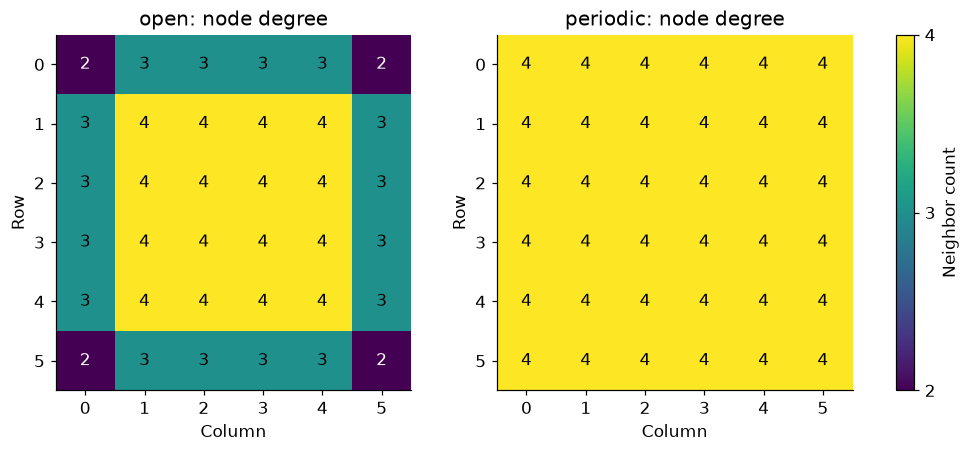

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import scipy, matplotlib
from scipy.integrate import solve_ivp
from scipy.sparse import csr_matrix
from IPython.display import display
import matplotlib.pyplot as plt
OUT=Path('results/fhn_lattice'); OUT.mkdir(parents=True,exist_ok=True)
SIDE=6; N=SIDE**2; A_REC,B_REC,EPS=.7,.8,.08
END,BURN=1200.,600.; DT=.5
SEEDS=[11,29]; STRENGTHS=[0.,.1,.4]
BLUE,ORANGE='#2166AC','#C56A18'
plt.rcParams.update({'font.size':11,'figure.dpi':110,'savefig.dpi':160,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
versions=dict(python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__)
print(versions)
def save(fig,name):
 fig.savefig(OUT/(name+'.png'),bbox_inches='tight');plt.show();plt.close(fig)
def adjacency(side,boundary):
 if side<3: raise ValueError('Use side >=3 to avoid ambiguous duplicate periodic neighbors')
 if boundary not in ('open','periodic'): raise ValueError('Unknown boundary')
 A=np.zeros((side*side,side*side))
 for r in range(side):
  for c in range(side):
   for dr,dc in [(1,0),(-1,0),(0,1),(0,-1)]:
    rr,cc=r+dr,c+dc
    if boundary=='periodic': rr%=side;cc%=side
    if 0<=rr<side and 0<=cc<side: A[r*side+c,rr*side+cc]=1
 return A
GRAPHS={bc:adjacency(SIDE,bc) for bc in ['open','periodic']}
def weights(A,mode):
 if mode=='per-edge': return A.copy()
 if mode=='normalized':
  deg=A.sum(axis=1);return np.divide(A,deg[:,None],out=np.zeros_like(A),where=deg[:,None]>0)
 raise ValueError('Unknown weight convention')
WEIGHTS={(bc,mode):weights(A,mode) for bc,A in GRAPHS.items() for mode in ['per-edge','normalized']}
rows=[]
for bc,A in GRAPHS.items():
 deg=A.sum(axis=1);L=np.diag(deg)-A;ev=np.linalg.eigvalsh(L)
 rows.append(dict(boundary=bc,nodes=N,undirected_edges=int(A.sum()/2),min_degree=deg.min(),max_degree=deg.max(),lambda2=ev[1],sufficient_raw_g_gt=1/ev[1]))
 for mode in ['per-edge','normalized']:
  pd.DataFrame(WEIGHTS[(bc,mode)]).to_csv(OUT/f'weights_{bc}_{mode}.csv',index=False)
graph_table=pd.DataFrame(rows);display(graph_table);graph_table.to_csv(OUT/'graph_summary.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(9,4),layout='constrained')
for ax,(bc,A) in zip(axs,GRAPHS.items()):
 im=ax.imshow(A.sum(axis=1).reshape(SIDE,SIDE),vmin=2,vmax=4,cmap='viridis')
 ax.set(title=f'{bc}: node degree',xlabel='Column',ylabel='Row');ax.grid(False)
 for r in range(SIDE):
  for c in range(SIDE): ax.text(c,r,int(A.sum(axis=1)[r*SIDE+c]),ha='center',va='center',color='white' if A.sum(axis=1)[r*SIDE+c]<3 else 'black')
fig.colorbar(im,ax=axs,ticks=[2,3,4],label='Neighbor count');save(fig,'01_boundary_degrees')

## 1. Integrate the full lattice and retain node events
A sparse matrix represents the interaction. All nodes evolve simultaneously under one adaptive ODE solver. There is no sequential update ordering, independent-node approximation, phase reduction or periodic reset.

In [3]:
def integrate(initial,W,g,end=END,method='DOP853',rtol=1e-8,atol=1e-10,current=.5):
 initial=np.asarray(initial,float);W=np.asarray(W,float);n=len(initial)
 if initial.shape!=(n,2) or W.shape!=(n,n): raise ValueError('Shape mismatch')
 if not np.isfinite(initial).all() or not np.isfinite(W).all() or np.any(W<0) or np.any(np.diag(W)!=0) or g<0: raise ValueError('Invalid state or coupling')
 sparse=csr_matrix(W);degree=W.sum(axis=1)
 def rhs(t,y):
  v,w=y.reshape(n,2).T
  return np.column_stack((v-v**3/3-w+current+g*(sparse@v-degree*v),EPS*(v+A_REC-B_REC*w))).ravel()
 events=[]
 for i in range(n):
  def crossing(t,y,index=i): return y[2*index]
  crossing.direction=1;crossing.terminal=False;events.append(crossing)
 sol=solve_ivp(rhs,(0,end),initial.ravel(),method=method,events=events,dense_output=True,
  rtol=rtol,atol=atol,max_step=.75)
 if not sol.success: raise RuntimeError(sol.message)
 return sol
isolated=integrate([[2.,-.5]],np.zeros((1,1)),0,end=800.,rtol=1e-10,atol=1e-12)
t0,t1=isolated.t_events[0][-2:];PERIOD=t1-t0
INITIAL={};initial_rows=[]
for seed in SEEDS:
 fractions=np.random.default_rng(seed).uniform(0,1,N)
 INITIAL[seed]=isolated.sol(t0+fractions*PERIOD).T
 for node,(q,z) in enumerate(zip(fractions,INITIAL[seed])):
  initial_rows.append(dict(seed=seed,node=node,row=node//SIDE,column=node%SIDE,phase_fraction=q,v=z[0],w=z[1]))
pd.DataFrame(initial_rows).to_csv(OUT/'initial_conditions.csv',index=False)
print('Isolated reference period:',PERIOD)
print('Initial phase fractions and full states saved for both seeds.')

Isolated reference period: 39.47441497981674
Initial phase fractions and full states saved for both seeds.


## 2. Define global, local and event-based observables
For each sampled time, define centered state variance
$$S^2(t)=N^{-1}\sum_i[(v_i-\bar v)^2+(w_i-\bar w)^2].$$
Report $\sqrt{\langle S^2\rangle_t}$ as global state spread. Local roughness is $\sqrt{\langle(v_i-v_j)^2\rangle_{t,\{i,j\}\in E}}$ using unweighted undirected adjacency edges; its edge set changes with boundary conditions. These observables have different meanings.

Event phases increase linearly by 2π between consecutive positive v=0 crossings. The global order parameter is $R(t)=|N^{-1}\sum_i e^{i\phi_i(t)}|$. Use only times supported by two bracketing events for **every** node; save the valid-time fraction. If any node lacks two events, phase metrics may be undefined. These interpolated phases are not isochron phases. Low R can reflect organized spatial phase patterns, not necessarily disorder.

Period-based node frequency is the reciprocal mean inter-event interval within the observation window (at least three events). Count frequencies have resolution 1/600 per node. No confidence intervals or wave-speed estimates are inferred.

In [5]:
def measure(sol,A,start=BURN,stop=END):
 times=np.arange(start,stop+DT/10,DT);n=len(A)
 z=sol.sol(times).reshape(n,2,-1);centered=z-z.mean(axis=0,keepdims=True)
 state_spread=float(np.sqrt(np.mean(np.sum(centered**2,axis=1))))
 ii,jj=np.where(np.triu(A,1)>0)
 roughness=float(np.sqrt(np.mean((z[ii,0]-z[jj,0])**2))) if len(ii) else np.nan
 phase=np.full((n,len(times)),np.nan);freq=[];count=[]
 for i,e in enumerate(sol.t_events):
  recent=e[(e>=start)&(e<=stop)];count.append(len(recent)/(stop-start))
  freq.append(1/np.diff(recent).mean() if len(recent)>=3 else np.nan)
  if len(e)>=2:
   mask=(times>=e[0])&(times<=e[-1]);phase[i,mask]=np.interp(times[mask],e,2*np.pi*np.arange(len(e)))
 valid=np.isfinite(phase).all(axis=0)
 R=np.abs(np.mean(np.exp(1j*phase[:,valid]),axis=0))
 finite_freq=np.asarray(freq)[np.isfinite(freq)]
 return dict(state_spread=state_spread,local_roughness=roughness,mean_phase_order=float(R.mean()) if len(R) else np.nan,
  phase_valid_fraction=float(valid.mean()),mean_period_frequency=float(finite_freq.mean()) if len(finite_freq) else np.nan,
  std_period_frequency=float(finite_freq.std()) if len(finite_freq) else np.nan,nodes_with_frequency=len(finite_freq),
  mean_count_frequency=float(np.mean(count)))
RUNS={};scan_rows=[];event_rows=[]
for seed in SEEDS:
 for (bc,mode),W in WEIGHTS.items():
  for g in STRENGTHS:
   sol=integrate(INITIAL[seed],W,g);RUNS[(seed,bc,mode,g)]=sol
   scan_rows.append(dict(seed=seed,boundary=bc,mode=mode,g=g,**measure(sol,GRAPHS[bc])))
   for node,events in enumerate(sol.t_events):
    event_rows.extend(dict(seed=seed,boundary=bc,mode=mode,g=g,node=node,time=float(t)) for t in events)
scan=pd.DataFrame(scan_rows);scan.to_csv(OUT/'coupling_scan.csv',index=False)
pd.DataFrame(event_rows).to_csv(OUT/'spike_events.csv',index=False)
display(scan[scan.seed==11].round(7))
print('Completed',len(scan),'full lattice runs.')

,seed,boundary,mode,g,state_spread,local_roughness,mean_phase_order,phase_valid_fraction,mean_period_frequency,std_period_frequency,nodes_with_frequency,mean_count_frequency
0,11,open,per-edge,0.0,1.448488e+00,1.872597e+00,0.068802,0.934222,0.025333,0.000000e+00,36,0.025232
1,11,open,per-edge,0.1,1.526800e-03,5.872000e-04,1.000000,0.951707,0.025333,5.000000e-07,36,0.025000
2,11,open,per-edge,0.4,0.000000e+00,0.000000e+00,1.000000,0.945878,0.025333,0.000000e+00,36,0.025000
3,11,open,normalized,0.0,1.448488e+00,1.872597e+00,0.068802,0.934222,0.025333,0.000000e+00,36,0.025232
4,11,open,normalized,0.1,1.370285e+00,9.096018e-01,0.355532,0.937552,0.026600,1.651000e-04,36,0.026713
5,11,open,normalized,0.4,3.675200e-03,1.422400e-03,0.999999,0.941715,0.025333,1.400000e-06,36,0.025000
6,11,periodic,per-edge,0.0,1.448488e+00,1.897469e+00,0.068802,0.934222,0.025333,0.000000e+00,36,0.025232
7,11,periodic,per-edge,0.1,2.000000e-07,1.000000e-07,1.000000,0.944213,0.025333,0.000000e+00,36,0.025000
8,11,periodic,per-edge,0.4,0.000000e+00,0.000000e+00,1.000000,0.943380,0.025333,0.000000e+00,36,0.025000
9,11,periodic,normalized,0.0,1.448488e+00,1.897469e+00,0.068802,0.934222,0.025333,0.000000e+00,36,0.025232


Completed 24 full lattice runs.


## 3. Compare the controlled cuts
Connected dots show the three sampled strengths, not a continued bifurcation branch. Thin solid/dashed traces show the two initial phase realizations independently. Comparing equal g across modes changes the total coupling coefficient; compare periodic per-edge 0.1 with normalized 0.4 for the exact matched control.

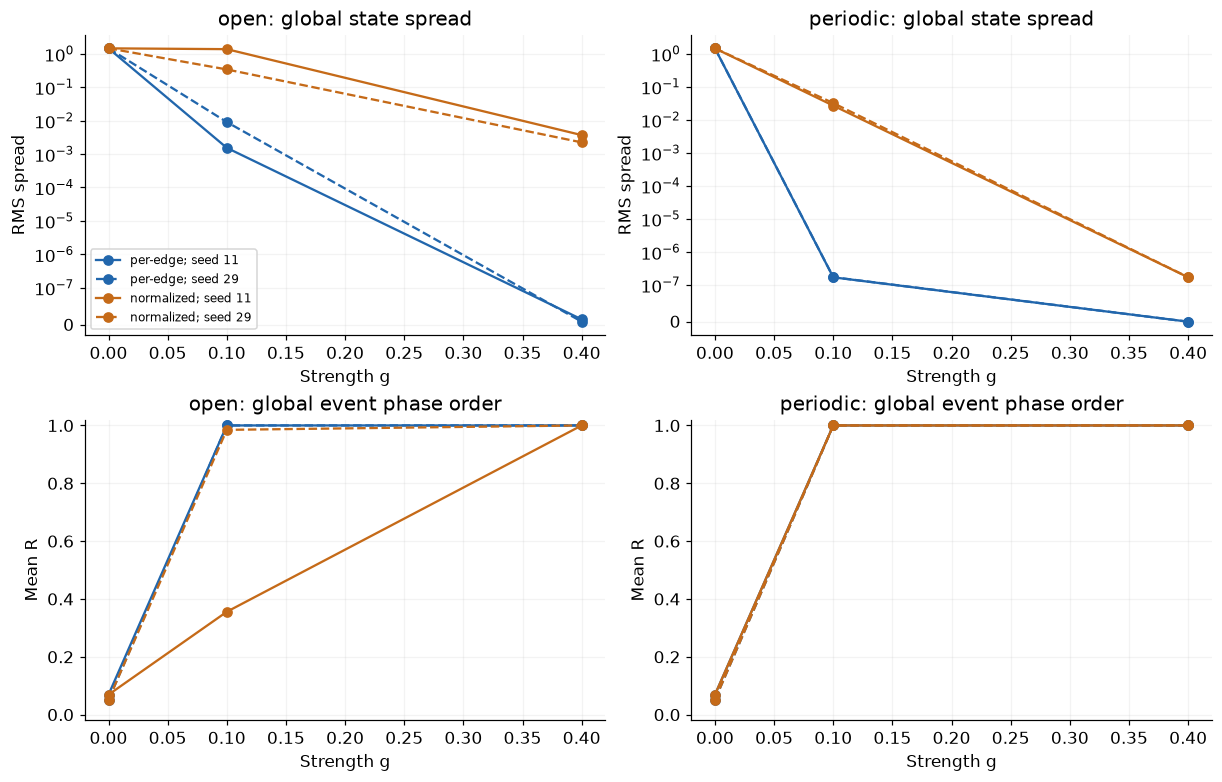

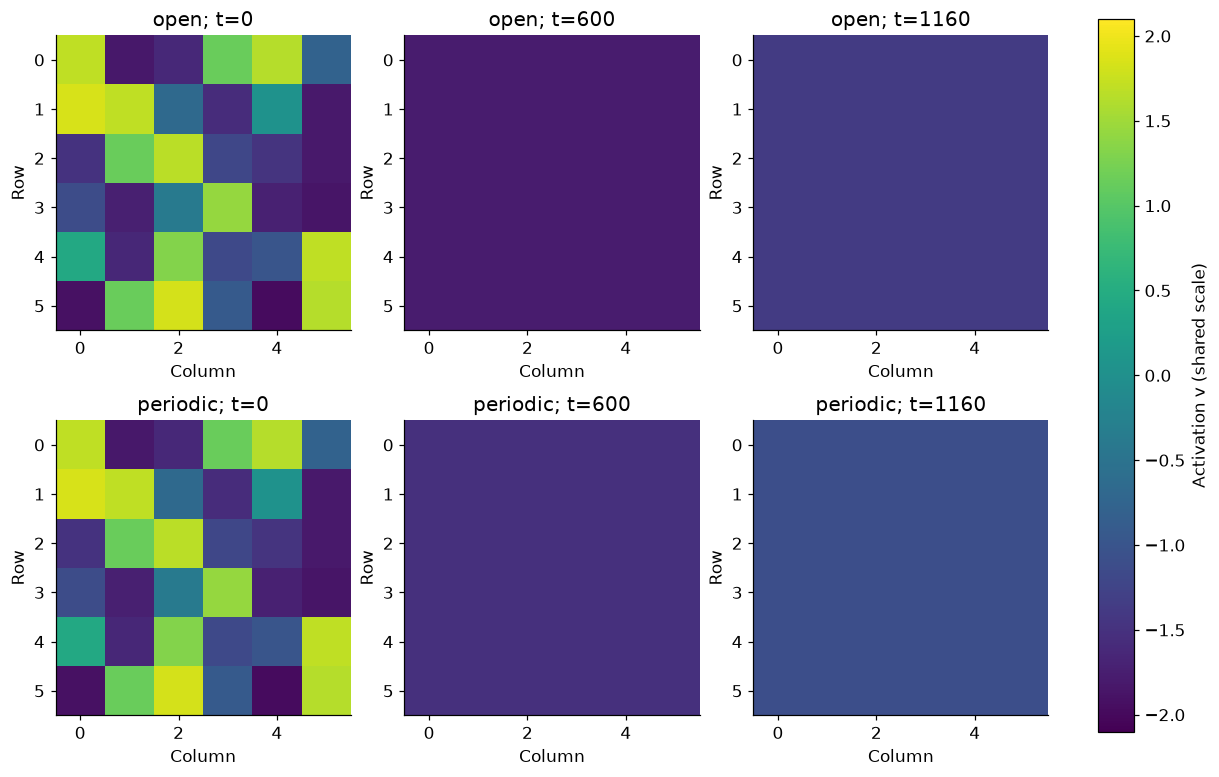

In [7]:
fig,axs=plt.subplots(2,2,figsize=(11,7),layout='constrained')
for col,bc in enumerate(['open','periodic']):
 for mode,color in [('per-edge',BLUE),('normalized',ORANGE)]:
  for seed,style in [(11,'-'),(29,'--')]:
   part=scan[(scan.boundary==bc)&(scan['mode']==mode)&(scan.seed==seed)]
   axs[0,col].plot(part.g,part.state_spread,'o'+style,color=color,label=f'{mode}; seed {seed}')
   axs[1,col].plot(part.g,part.mean_phase_order,'o'+style,color=color)
 axs[0,col].set(title=f'{bc}: global state spread',ylabel='RMS spread',xlabel='Strength g')
 axs[0,col].set_yscale('symlog',linthresh=1e-7)
 axs[1,col].set(title=f'{bc}: global event phase order',ylabel='Mean R',xlabel='Strength g',ylim=(-.02,1.02))
axs[0,0].legend(fontsize=8)
save(fig,'02_strength_and_normalization')
fig,axs=plt.subplots(2,3,figsize=(11,7),layout='constrained')
SNAP_TIMES=[0.,600.,1160.]
for r,bc in enumerate(['open','periodic']):
 sol=RUNS[(11,bc,'per-edge',.1)]
 for col,t in enumerate(SNAP_TIMES):
  im=axs[r,col].imshow(sol.sol(t).reshape(N,2)[:,0].reshape(SIDE,SIDE),vmin=-2.1,vmax=2.1,cmap='viridis')
  axs[r,col].set(title=f'{bc}; t={t:g}',xlabel='Column',ylabel='Row');axs[r,col].grid(False)
fig.colorbar(im,ax=axs.ravel().tolist(),label='Activation v (shared scale)')
save(fig,'03_spatial_snapshots')

## 4. Watch the evolution, not just its endpoint
The following spacetime plots use the central row (row index 3) for seed 11, per-edge g=0.1. They are slices of full-lattice dynamics. Apparent diagonal bands in a short slice alone do not establish a persistent traveling wave or its speed. The state spread includes all nodes; R uses all nodes and only supported event-phase times.

The two lower panels have independent vertical scales to show their respective transients. The logarithmic plotting floor is 10⁻¹⁴; values at the floor should not be interpreted as a physical precision limit.

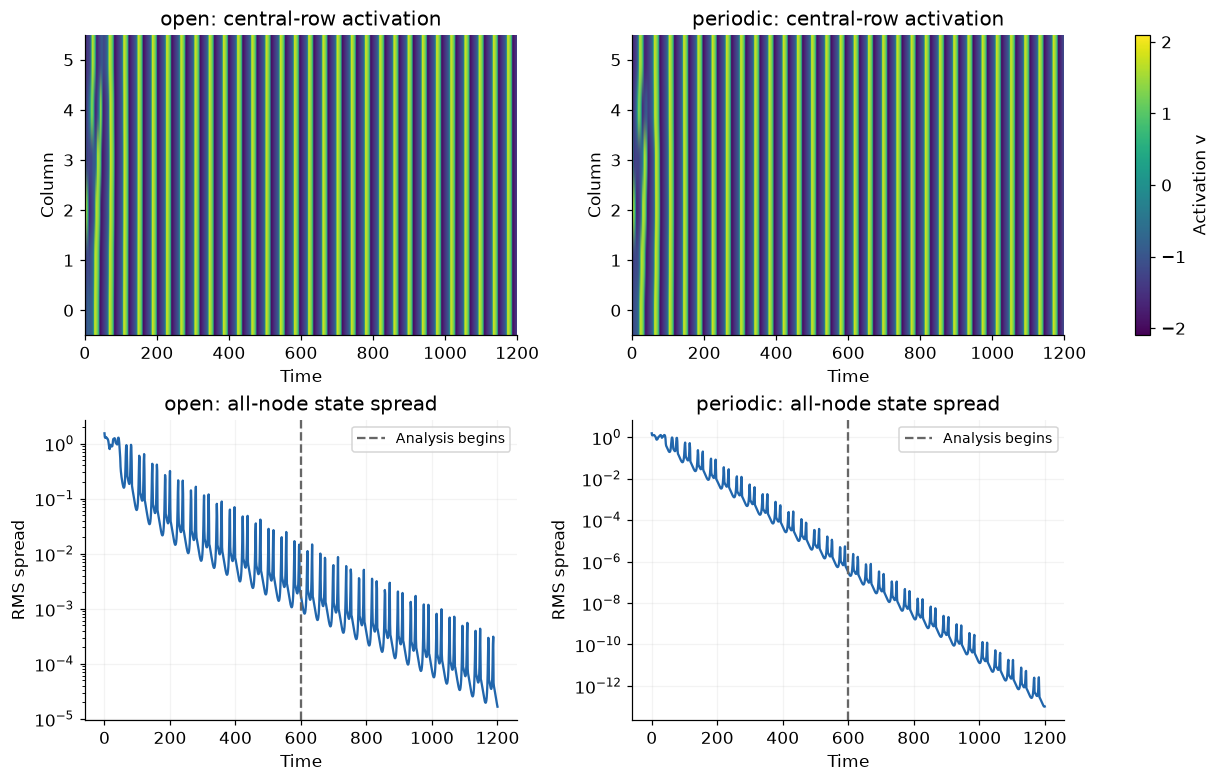

In [9]:
fig,axs=plt.subplots(2,2,figsize=(11,7),layout='constrained')
view=np.arange(0,END+.01,1.)
for col,bc in enumerate(['open','periodic']):
 sol=RUNS[(11,bc,'per-edge',.1)];z=sol.sol(view).reshape(N,2,-1)
 image=axs[0,col].imshow(z[(SIDE//2)*SIDE:(SIDE//2+1)*SIDE,0],aspect='auto',origin='lower',
  extent=[0,END,-.5,SIDE-.5],vmin=-2.1,vmax=2.1,cmap='viridis')
 axs[0,col].set(title=f'{bc}: central-row activation',xlabel='Time',ylabel='Column');axs[0,col].grid(False)
 center=z-z.mean(axis=0,keepdims=True);spread=np.sqrt(np.mean(np.sum(center**2,axis=1),axis=0))
 axs[1,col].semilogy(view,np.maximum(spread,1e-14),color=BLUE)
 axs[1,col].axvline(BURN,color='.4',linestyle='--',label='Analysis begins')
 axs[1,col].set(title=f'{bc}: all-node state spread',xlabel='Time',ylabel='RMS spread');axs[1,col].legend(fontsize=9)
fig.colorbar(image,ax=axs[0,:].tolist(),label='Activation v')
save(fig,'04_spacetime_and_transients')

## 5. Structural checks and numerical sensitivity
For raw symmetric coupling, $L=D-A$ has zero row sums and nonnegative spectrum. Summed diffusive input vanishes. Normalized open-grid weights are generally asymmetric; ordinary sum conservation fails, but the degree-weighted sum vanishes. The synchronous manifold remains invariant because every row uses differences.

For identical nodes on an undirected connected raw graph, let $E=\tfrac12\sum_i[(v_i-\bar v)^2+(w_i-\bar w)^2/\epsilon]$. Since the cubic is monotone, $\dot E\le(1-g\lambda_2)\|v-\bar v\|^2-b\|w-\bar w\|^2$. Thus $g\lambda_2>1$ is a sufficient global synchronization bound, not an onset estimate. The graph table reports it; the main scan need not exceed it. It does not directly apply to asymmetric normalized weights.

Check the periodic matched-weight identity on full trajectories, independent-node recovery, node permutation, event convergence against a tighter solver, and a later window. Numerical convergence is checked for a representative open raw g=0.4 case; other parameter cuts are not certified pointwise by that single test.

,check,error,limit,passed
0,open: symmetry,0.000000e+00,1.000000e-12,True
1,open: zero diagonal,0.000000e+00,1.000000e-12,True
2,open: Laplacian row sum,0.000000e+00,1.000000e-12,True
3,open: exact edge count,0.000000e+00,5.000000e-01,True
4,open: spectral formula,6.661338e-16,1.000000e-12,True
5,open: summed raw diffusion,0.000000e+00,1.000000e-10,True
6,open: normalized row sum,0.000000e+00,1.000000e-12,True
7,open: degree-weighted conservation,1.875833e-12,1.000000e-09,True
8,periodic: symmetry,0.000000e+00,1.000000e-12,True
9,periodic: zero diagonal,0.000000e+00,1.000000e-12,True


,window,state_spread,local_roughness,mean_phase_order,phase_valid_fraction,mean_period_frequency,std_period_frequency,nodes_with_frequency,mean_count_frequency
0,600–1200,1.526813e-03,5.871853e-04,1.0,0.951707,0.025333,4.953770e-07,36,0.025000
1,1800–2400,5.191547e-07,2.001986e-07,1.0,0.991674,0.025333,1.590985e-10,36,0.026667


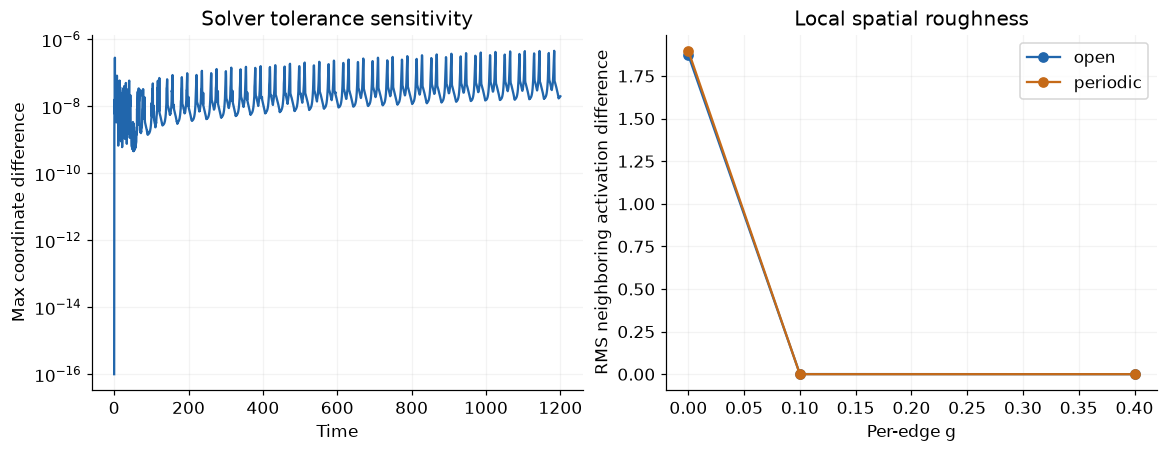

All 24 checks passed.


In [11]:
checks=[]
def check(name,error,limit): checks.append(dict(check=name,error=float(error),limit=limit,passed=bool(error<limit)))
for bc,A in GRAPHS.items():
 L=np.diag(A.sum(axis=1))-A
 check(f'{bc}: symmetry',np.max(abs(A-A.T)),1e-12)
 check(f'{bc}: zero diagonal',np.max(abs(np.diag(A))),1e-12)
 check(f'{bc}: Laplacian row sum',np.max(abs(L.sum(axis=1))),1e-12)
 expected=2*SIDE*(SIDE-1) if bc=='open' else 2*N
 check(f'{bc}: exact edge count',abs(A.sum()/2-expected),.5)
 check(f'{bc}: spectral formula',abs(np.linalg.eigvalsh(L)[1]-(2-2*np.cos(np.pi/SIDE) if bc=='open' else 2-2*np.cos(2*np.pi/SIDE))),1e-12)
 test=np.arange(N,dtype=float)**2;incoming=A@test-A.sum(axis=1)*test
 check(f'{bc}: summed raw diffusion',abs(incoming.sum()),1e-10)
 norm=WEIGHTS[(bc,'normalized')];inc=norm@test-test
 check(f'{bc}: normalized row sum',np.max(abs(norm.sum(axis=1)-1)),1e-12)
 check(f'{bc}: degree-weighted conservation',abs(np.dot(A.sum(axis=1),inc)),1e-9)
check('Periodic weight matching g=.1 / .4',np.max(abs(.1*WEIGHTS[('periodic','per-edge')]-.4*WEIGHTS[('periodic','normalized')])),1e-12)
test_t=np.linspace(0,END,2401)
check('Periodic matched trajectories',np.max(abs(RUNS[(11,'periodic','per-edge',.1)].sol(test_t)-RUNS[(11,'periodic','normalized',.4)].sol(test_t))),2e-6)
short=np.linspace(0,100,501);free=RUNS[(11,'open','per-edge',0.)]
for node in [0,N-1]:
 solo=integrate(INITIAL[11][node:node+1],np.zeros((1,1)),0,end=100.,rtol=1e-10,atol=1e-12)
 check(f'Independent recovery node {node}',np.max(abs(free.sol(short)[2*node:2*node+2]-solo.sol(short))),2e-5)
synchronous=integrate(np.tile(INITIAL[11][0],(N,1)),WEIGHTS[('open','normalized')],.4,end=100.)
z=synchronous.sol(short).reshape(N,2,-1)
check('Normalized synchronous manifold',np.max(abs(z-z[0])),1e-10)
# Permute both graph and node states; dynamics must commute with relabeling.
perm=np.random.default_rng(123).permutation(N);W=WEIGHTS[('open','per-edge')]
permuted=integrate(INITIAL[11][perm],W[np.ix_(perm,perm)],.4,end=100.)
base=RUNS[(11,'open','per-edge',.4)].sol(short).reshape(N,2,-1)
check('Node relabeling covariance',np.max(abs(permuted.sol(short).reshape(N,2,-1)-base[perm])),2e-5)
reference=integrate(INITIAL[11],W,.4,rtol=1e-10,atol=1e-12)
main=RUNS[(11,'open','per-edge',.4)]
check('Tighter DOP853 state convergence',np.max(abs(main.sol(test_t)-reference.sol(test_t))),2e-4)
event_error=0.
for e,er in zip(main.t_events,reference.t_events):
 assert len(e)==len(er)
 event_error=max(event_error,float(np.max(abs(e-er))))
check('Tighter DOP853 event convergence',event_error,2e-4)
validation=pd.DataFrame(checks);validation.to_csv(OUT/'validation_checks.csv',index=False);display(validation)
assert validation.passed.all()
long=integrate(INITIAL[11],WEIGHTS[('open','per-edge')],.1,end=2400.)
window=pd.DataFrame([dict(window='600–1200',**measure(RUNS[(11,'open','per-edge',.1)],GRAPHS['open'])),
 dict(window='1800–2400',**measure(long,GRAPHS['open'],1800.,2400.))])
window.to_csv(OUT/'window_sensitivity.csv',index=False);display(window)
fig,axs=plt.subplots(1,2,figsize=(10.5,4),layout='constrained')
err=np.max(abs(main.sol(test_t)-reference.sol(test_t)),axis=0)
axs[0].semilogy(test_t,np.maximum(err,1e-16),color=BLUE)
axs[0].set(xlabel='Time',ylabel='Max coordinate difference',title='Solver tolerance sensitivity')
for bc,color in [('open',BLUE),('periodic',ORANGE)]:
 part=scan[(scan.seed==11)&(scan.boundary==bc)&(scan['mode']=='per-edge')]
 axs[1].plot(part.g,part.local_roughness,'o-',color=color,label=bc)
axs[1].set(xlabel='Per-edge g',ylabel='RMS neighboring activation difference',title='Local spatial roughness');axs[1].legend()
save(fig,'05_convergence_and_local_roughness')
summary=dict(versions=versions,side=SIDE,nodes=N,spacing=1,parameters=dict(a=A_REC,b=B_REC,epsilon=EPS,current=.5),
 seeds=SEEDS,strengths=STRENGTHS,end=END,burn=BURN,sampling_step=DT,isolated_period=float(PERIOD),
 experiment_count=len(scan),checks_passed=int(validation.passed.sum()),event_convergence_error=event_error)
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
print('All',len(checks),'checks passed.')

## Next stage: distance-weighted coupling
Extend the same geometry with $W_{ij}=\mathbf1_{i\ne j}(1/d_{ij})^p$, optionally truncated at radius R. Compare p=2 with nearest neighbors and retain both raw and normalized conventions. Use Euclidean distances for open grids and minimum-image distances for periodic grids. The same-spacing cutoff R=1 should reproduce this notebook's adjacency exactly.

Then introduce excitatory/inhibitory source types with explicitly specified synaptic kinetics and input/output maps. No E/I ratio or reversal potential is implied by the present diffusion. Additional graph families and mixed node models follow after these controls.

### Provenance and limitations
Equations/parameters follow project notebooks 04 and 08; all graph construction, spectra and measurements are computed here. The square-grid spectra follow the path/cycle Cartesian sums: raw open eigenvalues $[2-2\cos(k\pi/L)]+[2-2\cos(l\pi/L)]$ and periodic $[2-2\cos(2k\pi/L)]+[2-2\cos(2l\pi/L)]$. Their exact checks do not establish dynamical stability outside the sufficient bound.

FHN context: [Neuronal Dynamics §4.3](https://neuronaldynamics.epfl.ch/online/Ch4.S3.html). Integration: [SciPy solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html). Project derivations and numerical results do not rely on supplied research PDFs. No continuum approximation, persistent wave/spiral classification, asymptotic basin survey, biological calibration or network-size generalization is established. Complete synchronization may require a much longer transient than this finite window. Two seeds do not justify statistical significance claims.